## Tarefa 2
# RPKM, FPKM e TPM na prática

**SCC02713 – Introdução à Bioinformática**

**Tarefa 2**

**Aluno: Gustavo Silva Lima**

**NUSP:16907230**

Neste notebook vamos calcular, passo a passo, as três métricas de normalização de RNA-Seq vistas em aula e comparar os resultados com tabelas e gráficos.

| Parte | O que fazemos |
|---|---|
| **1** | Reproduzimos o exemplo dos slides (4 genes, 3 amostras) e conferimos os números |
| **2** | Vemos por que o FPKM conta **fragmentos** e o RPKM conta **reads** |
| **3** | Aplicamos tudo a **dados reais**: 3 amostras de RNA-Seq de macrófagos humanos |
| **4** | Conclusões e exercícios |


In [1]:
# ---------------------------------------------------------------
# Bibliotecas usadas (todas já vêm instaladas no Google Colab)
# ---------------------------------------------------------------
import numpy as np                 # contas numéricas
import pandas as pd                # tabelas (DataFrames)
import matplotlib.pyplot as plt    # gráficos
from IPython.display import display, Markdown

# Aparência dos gráficos
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "font.size": 11,
})

# Uma cor fixa para cada métrica, igual ao longo de todo o notebook
CORES = {
    "Contagens": "#8BBF73",   # verde  (tabela "Counts" dos slides)
    "RPKM":      "#8E7CC3",   # roxo   (tabela "RPKM" dos slides)
    "FPKM":      "#4A86C5",   # azul
    "TPM":       "#E06666",   # vermelho (tabela "TPM" dos slides)
}
# Uma cor para cada gene do exemplo dos slides
CORES_GENES = {"A": "#6FA8DC", "B": "#E06666", "C": "#93C47D", "D": "#B7B7B7"}

def mostrar(df, casas=2, titulo=None):
    # Mostra uma tabela formatada com um número fixo de casas decimais
    if titulo:
        display(Markdown(f"**{titulo}**"))
    display(df.style.format(precision=casas))

---
# Parte 1 — O exemplo dos slides

Um experimento de RNA-Seq com **3 amostras** (réplicas) e um genoma com **4 genes** de tamanhos diferentes.

Lembre que a contagem bruta de um gene mistura três coisas:
1. **o quanto o gene é expresso** (o que queremos medir);
2. **o tamanho do gene**: genes maiores geram mais fragmentos;
3. **a profundidade de sequenciamento**: amostras sequenciadas com mais reads têm mais reads em todos os genes.

As métricas de normalização tentam remover os efeitos 2 e 3.

In [2]:
# ---------------------------------------------------------------
# Dados do exemplo dos slides
# ---------------------------------------------------------------
genes = ["A", "B", "C", "D"]

# Tamanho de cada gene, em quilobases (kb)
tamanho_kb = pd.Series([2, 4, 1, 10], index=genes, name="Tamanho (kb)")

# Contagem de reads de cada gene em cada amostra
contagens = pd.DataFrame(
    {"Rep1": [10, 20,  5, 0],
     "Rep2": [12, 25,  8, 0],
     "Rep3": [30, 60, 15, 1]},
    index=genes,
)

tabela = contagens.copy()
tabela.insert(0, "Tamanho (kb)", tamanho_kb)
mostrar(tabela, casas=0, titulo="Contagens brutas")

print("Total de reads por amostra:")
print(contagens.sum().to_string())

**Contagens brutas**

,Tamanho (kb),Rep1,Rep2,Rep3
A,2,10,12,30
B,4,20,25,60
C,1,5,8,15
D,10,0,0,1


Total de reads por amostra:
Rep1     35
Rep2     45
Rep3    106


Duas coisas chamam a atenção nos dados brutos:

* **Rep3 tem cerca de 3× mais reads em todos os genes**: ela foi sequenciada com mais profundidade (106 reads contra 35 e 45).
* **B tem sempre 2× mais reads que A**, mas B também é 2× maior que A.

### As fórmulas

Seja $c_g$ a contagem do gene $g$, $L_g$ o seu tamanho em kb e $N = \sum_g c_g$ o total de reads da amostra.

**RPKM** (primeiro a profundidade, depois o tamanho):

$$\text{RPKM}_g = \frac{c_g \,/\, (N / 10^6)}{L_g}$$

**TPM** (primeiro o tamanho, depois a profundidade):

$$\text{RPK}_g = \frac{c_g}{L_g} \qquad\qquad \text{TPM}_g = \frac{\text{RPK}_g}{\sum_g \text{RPK}_g \,/\, 10^6}$$

> Nos slides, como o exemplo tem pouquíssimas reads, o fator $10^6$ ("por milhão") foi trocado por **10** ("por dezena"). As funções abaixo têm um parâmetro `escala` para isso: usamos `escala=10` no exemplo dos slides e `escala=1e6` nos dados reais.

In [3]:
# ---------------------------------------------------------------
# Funções de normalização
# ---------------------------------------------------------------
# Convenção: linhas = genes, colunas = amostras.
# "comprimento_kb" pode ser uma Series (um tamanho por gene).

def rpm(contagens, escala=1e6):
    # Reads Por Milhão: corrige SÓ a profundidade de sequenciamento.
    # Divide cada coluna pelo seu total (em "milhões", ou na escala escolhida).
    fator = contagens.sum(axis=0) / escala
    return contagens / fator

def rpkm(contagens, comprimento_kb, escala=1e6):
    # Reads Por Kilobase por Milhão.
    # Passo 1: corrige a profundidade (RPM).
    # Passo 2: divide pelo tamanho do gene em kb.
    return rpm(contagens, escala).div(comprimento_kb, axis=0)

def fpkm(fragmentos, comprimento_kb, escala=1e6):
    # Fragmentos Por Kilobase por Milhão.
    # A conta é IDÊNTICA à do RPKM: a diferença está no que entra como contagem
    # (fragmentos em vez de reads). Veja a Parte 2.
    return rpkm(fragmentos, comprimento_kb, escala)

def rpk(contagens, comprimento_kb):
    # Reads Por Kilobase: corrige SÓ o tamanho do gene.
    return contagens.div(comprimento_kb, axis=0)

def tpm(contagens, comprimento_kb, escala=1e6):
    # Transcritos Por Milhão.
    # Passo 1: corrige o tamanho (RPK).
    # Passo 2: divide pelo total de RPK da amostra (na escala escolhida).
    taxa = rpk(contagens, comprimento_kb)
    return taxa / (taxa.sum(axis=0) / escala)

### RPKM, passo a passo

In [4]:
ESCALA_SLIDES = 10   # "por dezena" em vez de "por milhão", como nos slides

# Passo 1: profundidade -----------------------------------------
total = contagens.sum()
fator = total / ESCALA_SLIDES
mostrar(pd.DataFrame({"Total de reads": total, "Dezenas de reads (fator)": fator}).T,
        casas=1, titulo="Fator de escala de cada amostra")

rpm_slides = rpm(contagens, escala=ESCALA_SLIDES)
mostrar(rpm_slides, titulo="Passo 1 · RPM = contagem ÷ fator (corrige a profundidade)")

# Passo 2: tamanho do gene ---------------------------------------
rpkm_slides = rpkm(contagens, tamanho_kb, escala=ESCALA_SLIDES)
mostrar(rpkm_slides, casas=3, titulo="Passo 2 · RPKM = RPM ÷ tamanho em kb (corrige o tamanho)")

# Exemplo de uma conta, para conferir à mão
print(f"Gene A, Rep1: {contagens.loc['A','Rep1']} ÷ {fator['Rep1']:.1f} ÷ {tamanho_kb['A']} kb "
      f"= {rpkm_slides.loc['A','Rep1']:.2f}")

**Fator de escala de cada amostra**

,Rep1,Rep2,Rep3
Total de reads,35.0,45.0,106.0
Dezenas de reads (fator),3.5,4.5,10.6


**Passo 1 · RPM = contagem ÷ fator (corrige a profundidade)**

,Rep1,Rep2,Rep3
A,2.86,2.67,2.83
B,5.71,5.56,5.66
C,1.43,1.78,1.42
D,0.00,0.00,0.09


**Passo 2 · RPKM = RPM ÷ tamanho em kb (corrige o tamanho)**

,Rep1,Rep2,Rep3
A,1.429,1.333,1.415
B,1.429,1.389,1.415
C,1.429,1.778,1.415
D,0.000,0.000,0.009


Gene A, Rep1: 10 ÷ 3.5 ÷ 2 kb = 1.43


Depois do RPKM, **A, B e C ficam em torno de 1,4 nas três amostras**: as diferenças nas contagens vinham só do tamanho dos genes e da profundidade. O gene **D** praticamente não é expresso.

### TPM, passo a passo
A conta usa os mesmos ingredientes, mas **na ordem inversa**.

In [5]:
# Passo 1: tamanho do gene ---------------------------------------
rpk_slides = rpk(contagens, tamanho_kb)
mostrar(rpk_slides, titulo="Passo 1 · RPK = contagem ÷ tamanho em kb")

# Passo 2: profundidade (agora usando o total de RPK) -------------
total_rpk = rpk_slides.sum()
mostrar(pd.DataFrame({"Total de RPK": total_rpk,
                      "Dezenas de RPK (fator)": total_rpk / ESCALA_SLIDES}).T,
        casas=3, titulo="Fator de escala do TPM")

tpm_slides = tpm(contagens, tamanho_kb, escala=ESCALA_SLIDES)
mostrar(tpm_slides, casas=3, titulo="Passo 2 · TPM = RPK ÷ fator")

print(f"Gene A, Rep1: {rpk_slides.loc['A','Rep1']:.0f} ÷ {total_rpk['Rep1']/ESCALA_SLIDES:.2f} "
      f"= {tpm_slides.loc['A','Rep1']:.2f}")

**Passo 1 · RPK = contagem ÷ tamanho em kb**

,Rep1,Rep2,Rep3
A,5.00,6.00,15.00
B,5.00,6.25,15.00
C,5.00,8.00,15.00
D,0.00,0.00,0.10


**Fator de escala do TPM**

,Rep1,Rep2,Rep3
Total de RPK,15.000,20.250,45.100
Dezenas de RPK (fator),1.500,2.025,4.510


**Passo 2 · TPM = RPK ÷ fator**

,Rep1,Rep2,Rep3
A,3.333,2.963,3.326
B,3.333,3.086,3.326
C,3.333,3.951,3.326
D,0.000,0.000,0.022


Gene A, Rep1: 5 ÷ 1.50 = 3.33


### RPKM × TPM: a diferença está na soma das colunas

In [6]:
# Junta tudo em uma tabela só e acrescenta uma linha com a soma de cada coluna
comparacao = pd.concat(
    {"Contagens": contagens, "RPKM": rpkm_slides, "TPM": tpm_slides}, axis=1
)
comparacao.loc["Soma"] = comparacao.sum()
mostrar(comparacao, casas=3, titulo="Contagens, RPKM e TPM lado a lado")

**Contagens, RPKM e TPM lado a lado**

* A **soma das colunas de RPKM muda** de amostra para amostra (≈ 4,29 / 4,50 / 4,25).
* A **soma das colunas de TPM é sempre a mesma** (10, porque usamos a escala 10; com dados reais é sempre 1.000.000).

Por isso o TPM pode ser lido como **proporção**: "de cada 10 transcritos da amostra, quantos são do gene A?". Os gráficos abaixo mostram isso.

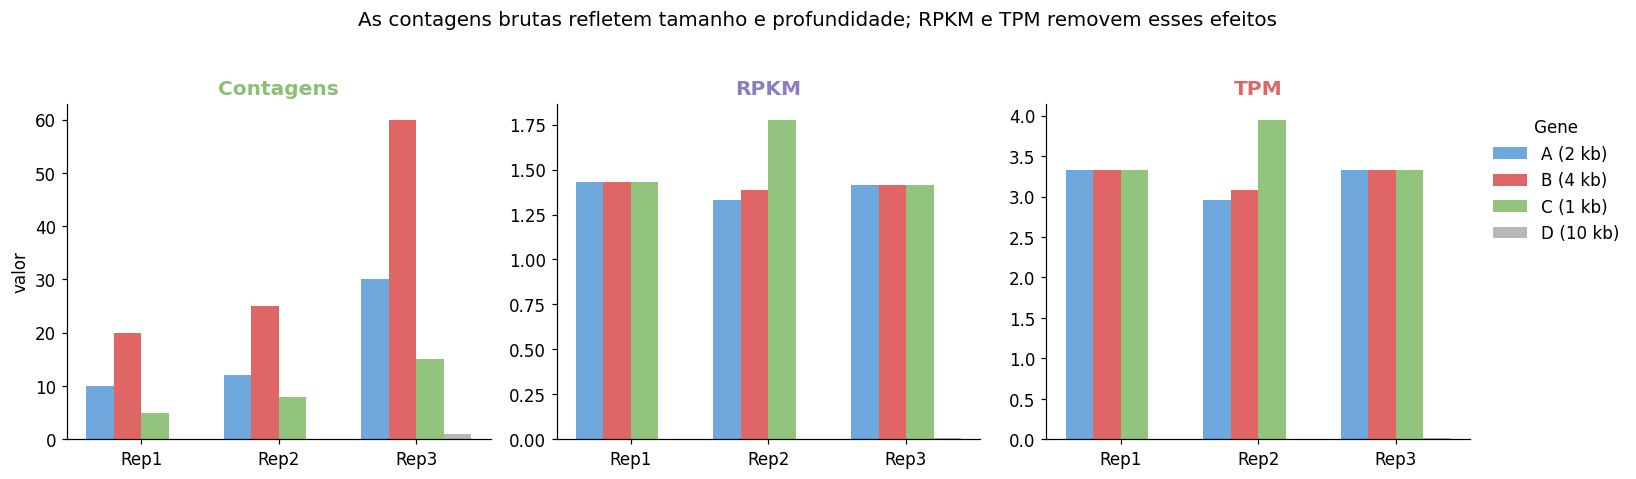

In [7]:
# ---------------------------------------------------------------
# Gráfico 1: o mesmo dado visto pelas três métricas
# ---------------------------------------------------------------
fig, eixos = plt.subplots(1, 3, figsize=(15, 4.2))
metricas = {"Contagens": contagens, "RPKM": rpkm_slides, "TPM": tpm_slides}
largura = 0.2
x = np.arange(contagens.shape[1])   # uma posição por amostra

for eixo, (nome, dados) in zip(eixos, metricas.items()):
    for i, gene in enumerate(genes):
        eixo.bar(x + (i - 1.5) * largura, dados.loc[gene], largura,
                 label=f"{gene} ({tamanho_kb[gene]} kb)", color=CORES_GENES[gene])
    eixo.set_xticks(x, dados.columns)
    eixo.set_title(nome, color=CORES[nome])

eixos[0].set_ylabel("valor")
eixos[2].legend(title="Gene", frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.suptitle("As contagens brutas refletem tamanho e profundidade; RPKM e TPM removem esses efeitos",
             y=1.03, fontsize=13)
plt.tight_layout()
plt.show()

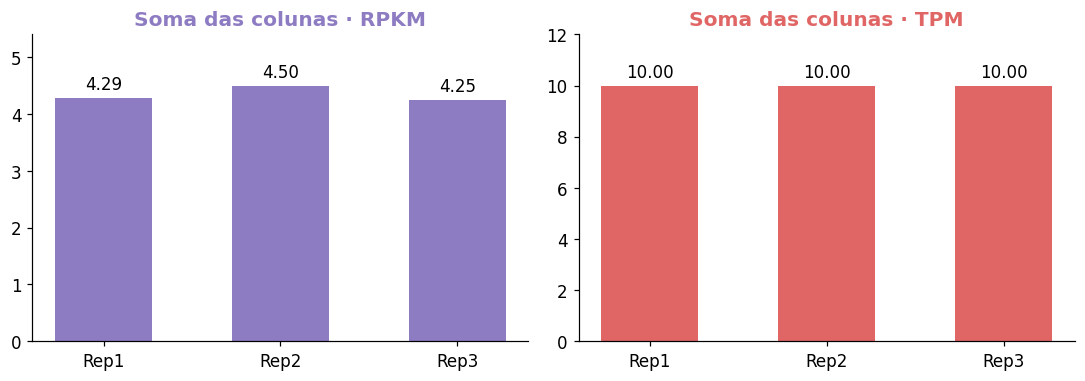

In [8]:
# ---------------------------------------------------------------
# Gráfico 2: soma das colunas
# ---------------------------------------------------------------
fig, eixos = plt.subplots(1, 2, figsize=(10, 3.6), sharey=False)
for eixo, (nome, dados) in zip(eixos, {"RPKM": rpkm_slides, "TPM": tpm_slides}.items()):
    somas = dados.sum()
    barras = eixo.bar(somas.index, somas, color=CORES[nome], width=0.55)
    eixo.bar_label(barras, fmt="%.2f", padding=3)
    eixo.set_title(f"Soma das colunas · {nome}", color=CORES[nome])
    eixo.set_ylim(0, somas.max() * 1.2)
plt.tight_layout()
plt.show()

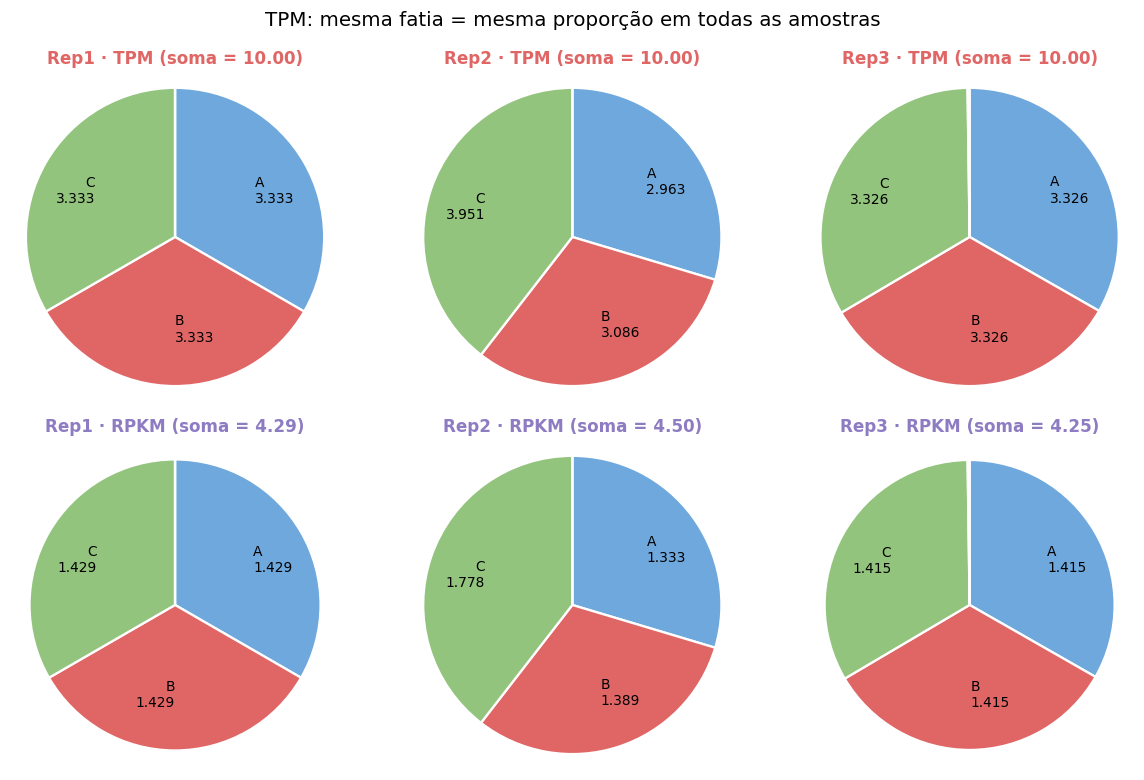

In [9]:
# ---------------------------------------------------------------
# Gráfico 3: as "pizzas" dos slides
# No TPM, todas as pizzas têm o mesmo tamanho (a soma é sempre 10).
# No RPKM, o tamanho total muda: desenhamos cada pizza com ÁREA
# proporcional à soma da coluna, como no slide.
# ---------------------------------------------------------------
fig, eixos = plt.subplots(2, 3, figsize=(11, 7.2))
soma_max = rpkm_slides.sum().max()

for linha, (nome, dados) in enumerate({"TPM": tpm_slides, "RPKM": rpkm_slides}.items()):
    for col, amostra in enumerate(dados.columns):
        eixo = eixos[linha, col]
        valores = dados[amostra]
        # raio proporcional à raiz da soma => área proporcional à soma
        raio = 1.0 if nome == "TPM" else np.sqrt(valores.sum() / soma_max)
        eixo.pie(valores.clip(lower=1e-9), radius=raio, startangle=90, counterclock=False,
                 colors=[CORES_GENES[g] for g in genes],
                 labels=[f"{g}\n{v:.3f}" if v > 0.05 else "" for g, v in valores.items()],
                 labeldistance=0.62, textprops={"fontsize": 9},
                 wedgeprops={"edgecolor": "white", "linewidth": 1.5})
        eixo.set_xlim(-1.1, 1.1); eixo.set_ylim(-1.1, 1.1)
        eixo.set_title(f"{amostra} · {nome} (soma = {valores.sum():.2f})",
                       color=CORES[nome], fontsize=11)

plt.suptitle("TPM: mesma fatia = mesma proporção em todas as amostras", fontsize=13)
plt.tight_layout()
plt.show()

**Leitura dos gráficos (como nos slides 20–22):**

* No TPM, uma fatia de 3,33 significa a **mesma proporção** em qualquer amostra. Fica fácil ver que o gene A ocupa uma fração um pouco maior do Rep1 (3,33) do que do Rep3 (3,326).
* No RPKM, cada amostra tem um "tamanho total" diferente, então o mesmo valor (por exemplo, 1,43) representa **proporções diferentes** em amostras diferentes. Aqui desenhamos cada pizza de RPKM com área proporcional à soma da coluna; como as somas são parecidas (4,25 a 4,50), as diferenças de tamanho são pequenas.

---
# Parte 2 — RPKM × FPKM: reads ou fragmentos?

* **Single-end:** cada fragmento gera **1 read** → contar reads ou fragmentos dá no mesmo.
* **Paired-end:** cada fragmento é lido pelas duas pontas e pode gerar **2 reads**. Às vezes só uma das pontas tem qualidade suficiente e alinha.

O FPKM conta cada **fragmento uma única vez**, porque cada fragmento é **uma molécula** de RNA capturada. Vamos ver o que acontece quando contamos reads em dados paired-end.

In [10]:
# ---------------------------------------------------------------
# Um experimento paired-end imaginário, com 3 genes igualmente expressos
# ---------------------------------------------------------------
# Para cada gene sabemos quantos FRAGMENTOS foram capturados e em quantos
# deles as DUAS pontas alinharam (nos demais, só uma ponta alinhou).
pe = pd.DataFrame({
    "Tamanho (kb)":          [2,   2,   1],
    "Fragmentos":            [100, 100, 50],
    "Fragm. c/ 2 pontas":    [100, 50,  50],   # gene Y: metade dos pares perdeu uma ponta
}, index=["X", "Y", "Z"])

# Cada fragmento com 2 pontas alinhadas vira 2 reads; os outros viram 1 read
pe["Reads"] = 2 * pe["Fragm. c/ 2 pontas"] + 1 * (pe["Fragmentos"] - pe["Fragm. c/ 2 pontas"])

# FPKM usa fragmentos; RPKM usa reads. A fórmula é a mesma!
pe["FPKM"] = fpkm(pe[["Fragmentos"]], pe["Tamanho (kb)"], escala=ESCALA_SLIDES)["Fragmentos"]
pe["RPKM (contando reads)"] = rpkm(pe[["Reads"]], pe["Tamanho (kb)"], escala=ESCALA_SLIDES)["Reads"]

mostrar(pe, casas=2, titulo="Reads × fragmentos em um experimento paired-end")

**Reads × fragmentos em um experimento paired-end**

,Tamanho (kb),Fragmentos,Fragm. c/ 2 pontas,Reads,FPKM,RPKM (contando reads)
X,2,100,100,200,2.00,2.22
Y,2,100,50,150,2.00,1.67
Z,1,50,50,100,2.00,2.22


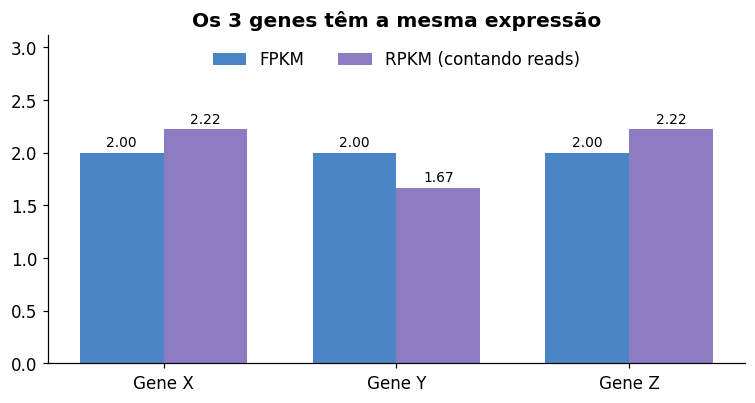

In [11]:
# ---------------------------------------------------------------
# Gráfico 4: FPKM × RPKM no experimento paired-end
# ---------------------------------------------------------------
fig, eixo = plt.subplots(figsize=(7, 3.8))
x = np.arange(len(pe))
for desloc, coluna, cor in [(-0.18, "FPKM", CORES["FPKM"]),
                            (+0.18, "RPKM (contando reads)", CORES["RPKM"])]:
    barras = eixo.bar(x + desloc, pe[coluna], 0.36, color=cor, label=coluna)
    eixo.bar_label(barras, fmt="%.2f", padding=2, fontsize=9)
eixo.set_xticks(x, [f"Gene {g}" for g in pe.index])
eixo.set_ylim(0, pe[["FPKM", "RPKM (contando reads)"]].max().max() * 1.4)
eixo.set_title("Os 3 genes têm a mesma expressão")
eixo.legend(frameon=False, loc="upper center", ncol=2)
plt.tight_layout()
plt.show()

* O **FPKM acerta**: os três genes têm o mesmo valor (2,00), porque têm a mesma densidade de moléculas capturadas.
* Contando **reads**, o gene **Y parece menos expresso** só porque, nele, muitas pontas não alinharam (por exemplo, por estar numa região repetitiva). X e Z, por outro lado, ficam inflados.
* Repare que se **todas** as pontas alinhassem, contar reads dobraria o numerador **e** o total, e o RPKM ficaria igual ao FPKM. O problema aparece justamente quando a taxa de alinhamento das pontas varia entre genes.

---
# Parte 3 — Dados reais

Vamos usar dados do estudo **Alasoo et al. (2018), *Nature Genetics***: RNA-Seq **paired-end** de **macrófagos humanos** (derivados de células-tronco pluripotentes induzidas). Escolhemos **3 amostras não estimuladas ("naive") de 3 doadores diferentes**, ou seja, 3 réplicas biológicas, como Rep1–Rep3 dos slides.

As reads foram quantificadas com o programa **Salmon** contra o transcriptoma de referência **Gencode v29**. Os arquivos vêm do pacote Bioconductor [`macrophage`](https://github.com/mikelove/macrophage) (Michael Love).

Para cada **transcrito**, o arquivo `quant.sf` do Salmon traz:

| Coluna | Significado |
|---|---|
| `Name` | identificador do transcrito (Ensembl) |
| `Length` | tamanho do transcrito, em nucleotídeos |
| `EffectiveLength` | tamanho "efetivo": desconta as posições onde um fragmento não cabe (ver célula de validação) |
| `TPM` | o TPM calculado pelo próprio Salmon |
| `NumReads` | número **estimado de fragmentos** do transcrito (apesar do nome!) |

Como os dados são paired-end e `NumReads` conta fragmentos, a métrica correta aqui é o **FPKM**.

In [12]:
# ---------------------------------------------------------------
# Download dos dados (arquivos públicos no GitHub)
# ---------------------------------------------------------------
# Fixamos uma versão (commit) do repositório para o resultado ser sempre o mesmo.
BASE = ("https://raw.githubusercontent.com/mikelove/macrophage/"
        "2ba828bcd733ad3c3c463c6829711cf3893a49dd/inst/extdata/")

# 3 macrófagos não estimulados ("naive"), de 3 doadores diferentes
AMOSTRAS = {
    "Rep1": {"id": "SAMEA103885284", "doador": "ieki"},
    "Rep2": {"id": "SAMEA103885102", "doador": "diku"},
    "Rep3": {"id": "SAMEA103885262", "doador": "qaqx"},
}

quant = {}
for rep, info in AMOSTRAS.items():
    url = f"{BASE}quants/{info['id']}/quant.sf.gz"
    print(f"Baixando {rep} ({info['id']}, doador {info['doador']})...")
    quant[rep] = pd.read_csv(url, sep="\t", index_col="Name")   # o pandas descompacta o .gz sozinho

print(f"\nCada arquivo tem {len(quant['Rep1']):,} transcritos.")
quant["Rep1"].head()

Baixando Rep1 (SAMEA103885284, doador ieki)...
Baixando Rep2 (SAMEA103885102, doador diku)...
Baixando Rep3 (SAMEA103885262, doador qaqx)...

Cada arquivo tem 205,870 transcritos.


,Length,EffectiveLength,TPM,NumReads
Name,,,,
ENST00000456328.2,1657,1502.019,0.855168,27.337
ENST00000450305.2,632,430.000,0.000000,0.000
ENST00000488147.1,1351,1176.999,9.985373,250.127
ENST00000619216.1,68,17.000,0.000000,0.000
ENST00000473358.1,712,517.402,0.387239,4.264


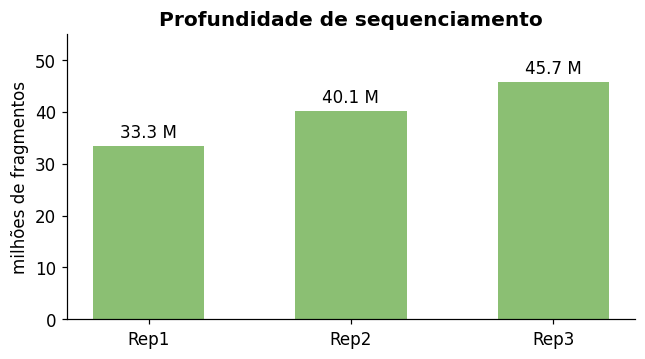

Rep3 foi sequenciada com 1.37× mais fragmentos que Rep1.


In [13]:
# ---------------------------------------------------------------
# Profundidade de sequenciamento de cada amostra
# ---------------------------------------------------------------
# Somando os fragmentos estimados de todos os transcritos, temos o total da amostra
fragmentos_totais = pd.Series({rep: q["NumReads"].sum() for rep, q in quant.items()})

fig, eixo = plt.subplots(figsize=(6, 3.4))
barras = eixo.bar(fragmentos_totais.index, fragmentos_totais / 1e6,
                  color=CORES["Contagens"], width=0.55)
eixo.bar_label(barras, fmt="%.1f M", padding=3)
eixo.set_ylabel("milhões de fragmentos")
eixo.set_ylim(0, fragmentos_totais.max() / 1e6 * 1.2)
eixo.set_title("Profundidade de sequenciamento")
plt.tight_layout()
plt.show()

print(f"Rep3 foi sequenciada com {fragmentos_totais['Rep3'] / fragmentos_totais['Rep1']:.2f}× "
      "mais fragmentos que Rep1.")

### Validação: conseguimos reproduzir o TPM do Salmon?

Antes de seguir, vamos conferir se a **nossa** função `tpm()` dá o mesmo resultado que o Salmon. Um detalhe: o Salmon usa o **tamanho efetivo** do transcrito. Como um fragmento tem em média algumas centenas de nucleotídeos, ele não consegue começar nas últimas posições do transcrito; o tamanho efetivo desconta essas posições. Para transcritos longos, a diferença é pequena; para os curtos, é grande.

Maior diferença entre o nosso TPM e o do Salmon: 0.0269 TPM
(as diferenças vêm só do arredondamento dos números gravados no arquivo)


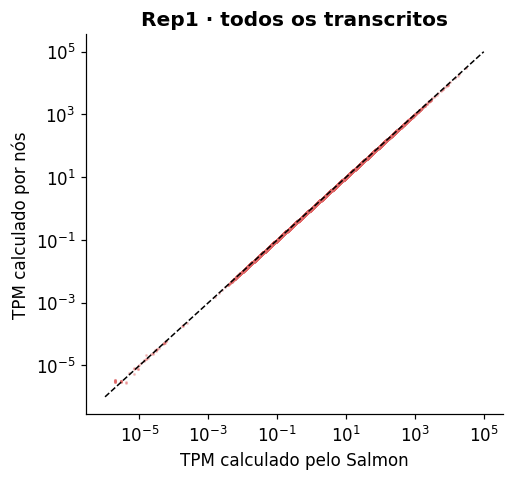

In [14]:
q = quant["Rep1"]
nosso_tpm = tpm(q[["NumReads"]], q["EffectiveLength"] / 1000)["NumReads"]

diferenca = (nosso_tpm - q["TPM"]).abs()
print(f"Maior diferença entre o nosso TPM e o do Salmon: {diferenca.max():.4f} TPM")
print("(as diferenças vêm só do arredondamento dos números gravados no arquivo)")

expressos = q["TPM"] > 0
fig, eixo = plt.subplots(figsize=(4.8, 4.5))
eixo.loglog(q.loc[expressos, "TPM"], nosso_tpm[expressos], ".", ms=2, alpha=0.3,
            color=CORES["TPM"])
lim = [1e-6, 1e5]
eixo.plot(lim, lim, "k--", lw=1)
eixo.set_xlabel("TPM calculado pelo Salmon")
eixo.set_ylabel("TPM calculado por nós")
eixo.set_title("Rep1 · todos os transcritos")
plt.tight_layout()
plt.show()

Os pontos caem sobre a diagonal: nossa função reproduz o Salmon.

### Do transcrito para o gene

Um gene pode ter vários transcritos (isoformas, lembra do splicing alternativo?). Para trabalhar no nível de **gene**, como nos slides:

* **contagem do gene** = soma dos fragmentos de todos os seus transcritos;
* **tamanho do gene** = média dos tamanhos dos seus transcritos, **ponderada pela expressão** de cada um (é o que faz o pacote `tximport`). Assim, a isoforma mais expressa pesa mais. Para simplificar, usamos um tamanho único por gene: a média entre as 3 amostras.

Para saber a que gene pertence cada transcrito, usamos a anotação Gencode v29 (arquivo GTF).

In [15]:
# ---------------------------------------------------------------
# Anotação: transcrito -> gene
# ---------------------------------------------------------------
gtf = pd.read_csv(BASE + "gencode.v29.annotation.slim.gtf.gz", sep="\t",
                  comment="#", header=None, usecols=[2, 8], names=["tipo", "atributos"])
gtf = gtf[gtf["tipo"] == "transcript"]

# A última coluna do GTF é um texto do tipo: gene_id "..."; transcript_id "..."; gene_name "...";
anotacao = pd.DataFrame({
    "transcrito": gtf["atributos"].str.extract(r'transcript_id "([^"]+)"')[0],
    "gene":       gtf["atributos"].str.extract(r'gene_name "([^"]+)"')[0],
}).set_index("transcrito")

print(f"{len(anotacao):,} transcritos de {anotacao['gene'].nunique():,} genes")
anotacao.head()

206,694 transcritos de 57,133 genes


,gene
transcrito,
ENST00000456328.2,DDX11L1
ENST00000450305.2,DDX11L1
ENST00000488147.1,WASH7P
ENST00000619216.1,MIR6859-1
ENST00000473358.1,MIR1302-2HG


In [16]:
# ---------------------------------------------------------------
# Tabelas no nível de transcrito (linhas = transcritos, colunas = amostras)
# ---------------------------------------------------------------
frag_tx = pd.DataFrame({rep: q["NumReads"] for rep, q in quant.items()})   # fragmentos
tpm_tx  = pd.DataFrame({rep: q["TPM"]      for rep, q in quant.items()})   # para os pesos
tam_tx  = quant["Rep1"]["Length"]                                          # igual nas 3 amostras

gene_de = anotacao.loc[frag_tx.index, "gene"]   # o gene de cada transcrito

# Contagem do gene = soma dos fragmentos dos seus transcritos
frag_gene = frag_tx.groupby(gene_de).sum()

# Tamanho do gene = média dos tamanhos dos transcritos ponderada pelo TPM
pesos = tpm_tx + 1e-9                     # +1e-9 evita divisão por zero em genes não expressos
tam_ponderado = pesos.mul(tam_tx, axis=0).groupby(gene_de).sum() / pesos.groupby(gene_de).sum()
tamanho_gene_kb = tam_ponderado.mean(axis=1) / 1000

print(f"{len(frag_gene):,} genes")
mostrar(frag_gene.loc[["ACTB", "GAPDH", "CD14"]], casas=0,
        titulo="Exemplo: fragmentos por gene")

56,809 genes


**Exemplo: fragmentos por gene**

,Rep1,Rep2,Rep3
gene,,,
ACTB,520852,581799,486479
GAPDH,78643,74161,151885
CD14,61825,77898,28765


In [17]:
# ---------------------------------------------------------------
# Normalização com as MESMAS funções da Parte 1, agora "por milhão"
# ---------------------------------------------------------------
fpkm_gene = fpkm(frag_gene, tamanho_gene_kb, escala=1e6)
tpm_gene  = tpm(frag_gene,  tamanho_gene_kb, escala=1e6)

# Genes escolhidos para ilustrar: têm expressão PARECIDA e ESTÁVEL nos 3 doadores,
# mas tamanhos bem diferentes (de 0,6 a 4,7 kb). São o "A, B e C" dos dados reais.
selecao = ["ATP5PD", "GPX4", "SEPT9", "NCOR2", "PJA2"]

tabela_real = pd.concat(
    {"Tamanho (kb)": tamanho_gene_kb.loc[selecao].to_frame("kb"),
     "Fragmentos":   frag_gene.loc[selecao],
     "FPKM":         fpkm_gene.loc[selecao],
     "TPM":          tpm_gene.loc[selecao]}, axis=1)
mostrar(tabela_real, casas=1, titulo="Genes selecionados · 3 réplicas")

**Genes selecionados · 3 réplicas**

### Efeito 1: profundidade de sequenciamento

Escolhemos 5 genes cuja expressão é parecida e estável nos 3 doadores, mas de tamanhos muito diferentes, como os genes A, B e C dos slides. Repare em duas coisas no gráfico abaixo:

* pela **contagem bruta**, todos parecem **subir** de Rep1 para Rep3, mas isso é só porque Rep3 foi sequenciada com mais profundidade;
* pela contagem bruta, os genes **longos** (SEPT9, NCOR2) parecem muito mais expressos que os **curtos** (ATP5PD, GPX4).

Depois da normalização, os valores ficam **estáveis entre as réplicas** e **parecidos entre os genes**.

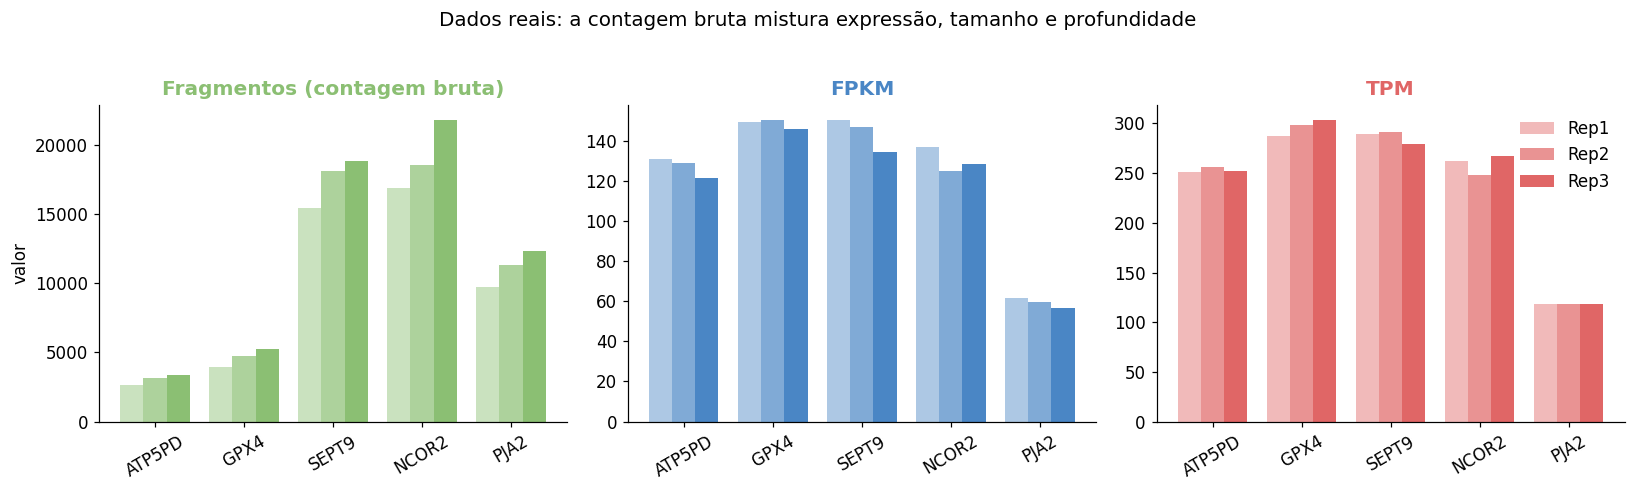

In [18]:
# ---------------------------------------------------------------
# Gráfico 5: genes selecionados pelas três lentes
# ---------------------------------------------------------------
fig, eixos = plt.subplots(1, 3, figsize=(15, 4.3))
paineis = {"Fragmentos (contagem bruta)": (frag_gene, "Contagens"),
           "FPKM": (fpkm_gene, "FPKM"),
           "TPM":  (tpm_gene,  "TPM")}
largura = 0.26
x = np.arange(len(selecao))
tons = [0.45, 0.7, 1.0]   # tons mais claros -> mais escuros para Rep1, Rep2, Rep3

for eixo, (titulo, (dados, cor)) in zip(eixos, paineis.items()):
    for i, rep in enumerate(dados.columns):
        eixo.bar(x + (i - 1) * largura, dados.loc[selecao, rep], largura,
                 color=CORES[cor], alpha=tons[i], label=rep)
    eixo.set_xticks(x, selecao, rotation=30)
    eixo.set_title(titulo, color=CORES[cor])
    eixo.ticklabel_format(axis="y", style="plain")

eixos[0].set_ylabel("valor")
eixos[2].legend(frameon=False)
fig.suptitle("Dados reais: a contagem bruta mistura expressão, tamanho e profundidade",
             y=1.03, fontsize=13)
plt.tight_layout()
plt.show()

### Efeito 2: tamanho do gene

Comparando dois genes da seleção em Rep1: **NCOR2** recebeu cerca de **4× mais fragmentos** que **GPX4**. Mas NCOR2 também é cerca de 4,7× maior. Corrigindo pelo tamanho, os dois têm **expressão parecida**: é a situação dos genes A e B dos slides, agora com dados reais.

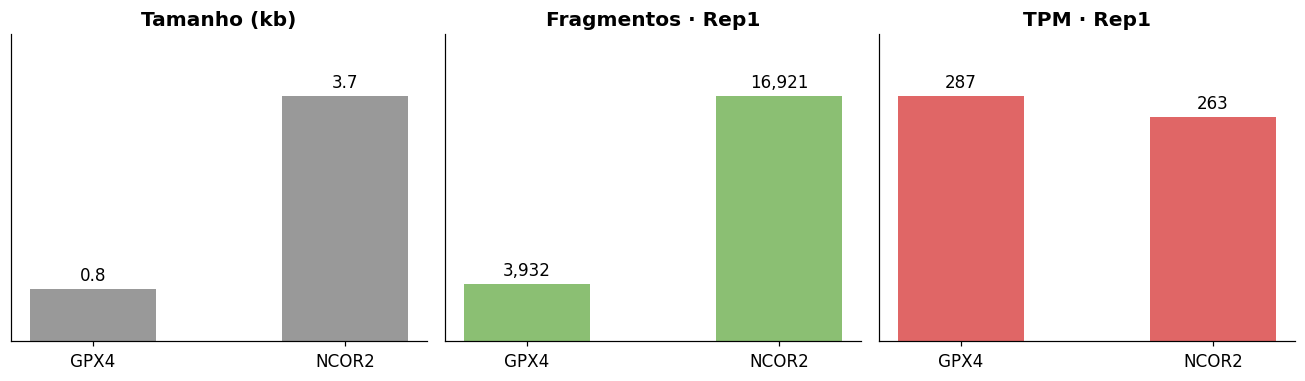

In [19]:
# ---------------------------------------------------------------
# Gráfico 6: muitos mais fragmentos, mesma expressão
# ---------------------------------------------------------------
par = ["GPX4", "NCOR2"]
rep = "Rep1"
fig, eixos = plt.subplots(1, 3, figsize=(12, 3.6))
for eixo, (titulo, valores, cor) in zip(eixos, [
        ("Tamanho (kb)",       tamanho_gene_kb.loc[par], "#999999"),
        (f"Fragmentos · {rep}", frag_gene.loc[par, rep],  CORES["Contagens"]),
        (f"TPM · {rep}",        tpm_gene.loc[par, rep],   CORES["TPM"])]):
    barras = eixo.bar(par, valores, color=cor, width=0.5)
    eixo.bar_label(barras, fmt="{:,.1f}" if "kb" in titulo else "{:,.0f}", padding=3)
    eixo.set_ylim(0, valores.max() * 1.25)
    eixo.set_title(titulo)
    eixo.set_yticks([])
plt.tight_layout()
plt.show()

### Efeito 3: FPKM × TPM nos dados reais

Assim como no exemplo dos slides, a **soma das colunas de FPKM muda** entre as amostras, enquanto a do **TPM é sempre 1.000.000**.

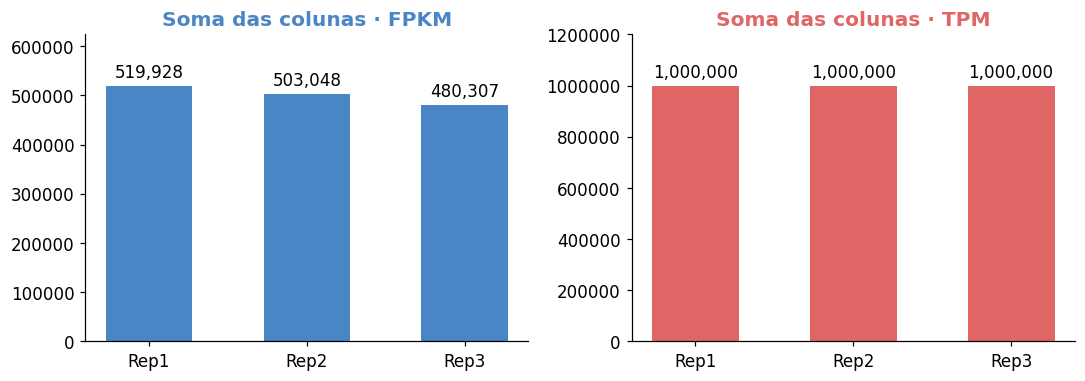

In [20]:
# ---------------------------------------------------------------
# Gráfico 7: soma das colunas
# ---------------------------------------------------------------
fig, eixos = plt.subplots(1, 2, figsize=(10, 3.6))
for eixo, (nome, dados) in zip(eixos, {"FPKM": fpkm_gene, "TPM": tpm_gene}.items()):
    somas = dados.sum()
    barras = eixo.bar(somas.index, somas, color=CORES[nome], width=0.55)
    eixo.bar_label(barras, labels=[f"{v:,.0f}" for v in somas], padding=3)
    eixo.set_ylim(0, somas.max() * 1.2)
    eixo.set_title(f"Soma das colunas · {nome}", color=CORES[nome])
    eixo.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()

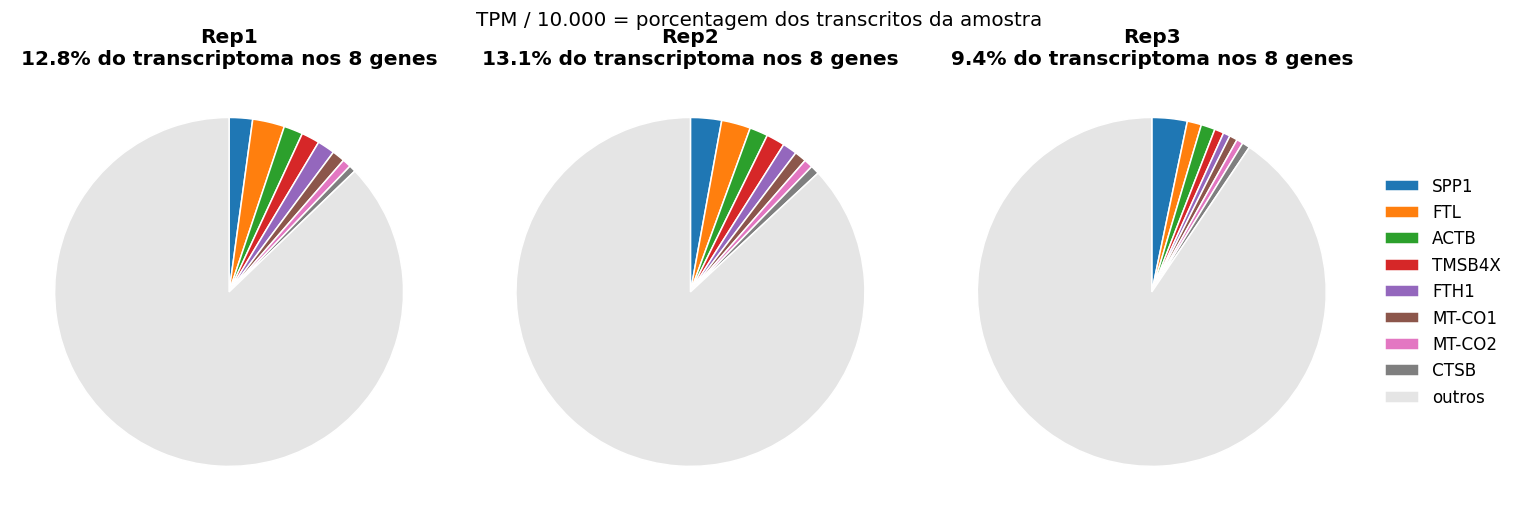

**Porcentagem do transcriptoma (TPM ÷ 10.000)**

,Rep1,Rep2,Rep3
gene,,,
SPP1,2.17,2.88,3.27
FTL,2.96,2.69,1.32
ACTB,1.76,1.69,1.30
TMSB4X,1.69,1.72,0.86
FTH1,1.62,1.34,0.64
MT-CO1,1.18,1.10,0.74
MT-CO2,0.80,0.82,0.60
CTSB,0.63,0.83,0.71


In [21]:
# ---------------------------------------------------------------
# Gráfico 8: o TPM como proporção do transcriptoma
# Os 8 genes mais expressos (em média) e o resto como "outros"
# ---------------------------------------------------------------
top = tpm_gene.mean(axis=1).nlargest(8).index
fig, eixos = plt.subplots(1, 3, figsize=(14, 4.8))
paleta = plt.cm.tab10.colors

for eixo, rep in zip(eixos, tpm_gene.columns):
    fatias = tpm_gene.loc[top, rep].copy()
    fatias["outros"] = tpm_gene[rep].sum() - fatias.sum()
    eixo.pie(fatias, startangle=90, counterclock=False,
             colors=list(paleta[:8]) + ["#E5E5E5"],
             wedgeprops={"edgecolor": "white", "linewidth": 1})
    eixo.set_title(f"{rep}\n{fatias[:-1].sum() / 1e4:.1f}% do transcriptoma nos 8 genes")

eixos[2].legend(fatias.index, frameon=False, bbox_to_anchor=(1.0, 0.5), loc="center left")
plt.suptitle("TPM / 10.000 = porcentagem dos transcritos da amostra", fontsize=13)
plt.tight_layout()
plt.show()

mostrar((tpm_gene.loc[top] / 1e4), casas=2, titulo="Porcentagem do transcriptoma (TPM ÷ 10.000)")

### Visão geral: comparando duas réplicas gene a gene

Se as réplicas são parecidas, cada gene deveria cair perto da diagonal quando comparamos Rep1 e Rep3. Com a **contagem bruta**, a nuvem fica **deslocada para cima** (Rep3 tem mais fragmentos em quase todos os genes). Com o **TPM**, ela se aproxima bem mais da diagonal. O título de cada painel mostra a mediana da razão Rep3/Rep1: 1,00 seria nenhum deslocamento.

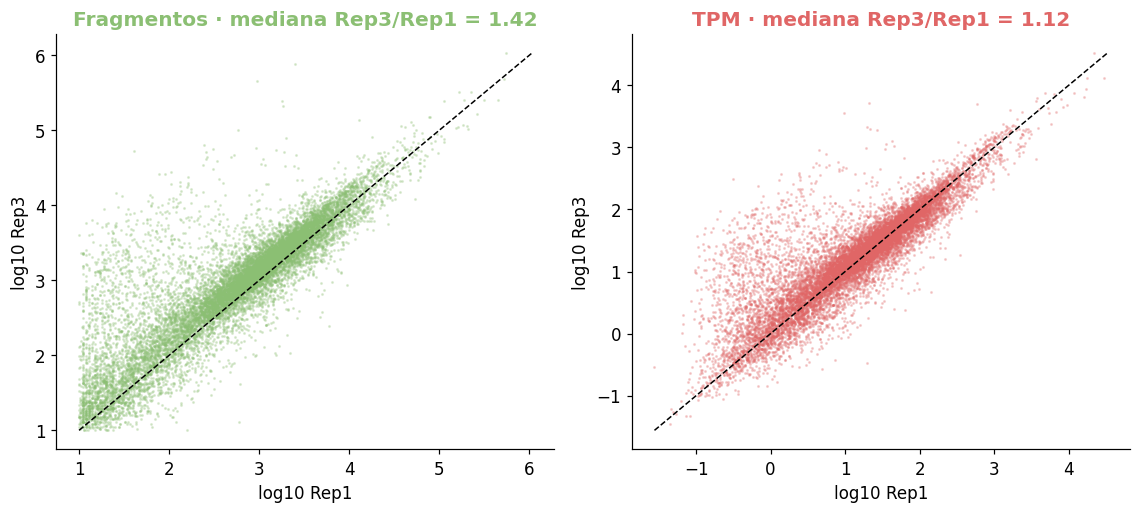

14,217 genes com pelo menos 10 fragmentos nas 3 amostras


In [22]:
# ---------------------------------------------------------------
# Gráfico 9: Rep1 × Rep3, contagem bruta e TPM (escala log)
# ---------------------------------------------------------------
expressos = (frag_gene > 10).all(axis=1)    # só genes com pelo menos 10 fragmentos em todas
fig, eixos = plt.subplots(1, 2, figsize=(10.5, 4.8))

for eixo, (nome, dados, cor) in zip(eixos, [("Fragmentos", frag_gene, CORES["Contagens"]),
                                            ("TPM",        tpm_gene,  CORES["TPM"])]):
    x1 = np.log10(dados.loc[expressos, "Rep1"])
    x3 = np.log10(dados.loc[expressos, "Rep3"])
    eixo.plot(x1, x3, ".", ms=2, alpha=0.25, color=cor)
    lim = [min(x1.min(), x3.min()), max(x1.max(), x3.max())]
    eixo.plot(lim, lim, "k--", lw=1)
    # mediana da razão Rep3/Rep1: 1,0 = sem deslocamento
    razao = 10 ** np.median(x3 - x1)
    eixo.set_title(f"{nome} · mediana Rep3/Rep1 = {razao:.2f}", color=cor)
    eixo.set_xlabel("log10 Rep1")
    eixo.set_ylabel("log10 Rep3")

plt.tight_layout()
plt.show()
print(f"{expressos.sum():,} genes com pelo menos 10 fragmentos nas 3 amostras")

Por que o TPM não chega exatamente a 1,00? Volte ao gráfico das pizzas: em Rep1, os 8 genes mais expressos ocupam cerca de 13% do transcriptoma; em Rep3, só cerca de 9%. Como o TPM é uma **proporção** (a soma é sempre 1 milhão), quando poucos genes muito expressos "ocupam menos espaço", **todos os outros ganham uma fatia um pouco maior**. É o **efeito de composição**, uma limitação conhecida de RPKM, FPKM e TPM, e o motivo de DESeq2 e edgeR usarem fatores de escala mais robustos.

Note também que, mesmo depois da normalização, a nuvem não é uma linha perfeita: são **3 pessoas diferentes**, e existe **variação biológica real** entre doadores. Normalizar remove os vieses técnicos (tamanho e profundidade), não as diferenças biológicas. Veja, por exemplo, `tpm_gene.loc[["CD14", "MRC1", "FN1"]]`: esses genes variam bastante de um doador para outro.

---
# Parte 4 — Conclusões

| | RPKM | FPKM | TPM |
|---|---|---|---|
| Conta | reads | fragmentos | reads ou fragmentos |
| Uso típico | single-end | paired-end | qualquer |
| Ordem das contas | profundidade → tamanho | profundidade → tamanho | tamanho → profundidade |
| Soma das colunas | varia | varia | sempre 10⁶ |
| Interpretação | densidade de reads | densidade de fragmentos | **proporção** dos transcritos |

* As três corrigem **tamanho do gene** e **profundidade de sequenciamento**, e servem para comparar **genes diferentes** e ter uma ideia da expressão entre amostras.
* O **TPM** é hoje o mais usado, porque seus valores são proporções diretamente comparáveis entre amostras.
* Para **testes de expressão diferencial**, ferramentas como **DESeq2** e **edgeR** não usam nenhuma das três: partem das **contagens brutas** e usam fatores de escala próprios, mais robustos.

### Exercícios
1. Na Parte 1, troque a contagem do gene D no Rep3 de 1 para 50. O que acontece com o RPKM e o TPM **dos outros genes** do Rep3? Por quê?
2. Na Parte 2, faça o gene Z perder uma ponta em todos os seus fragmentos. Qual gene parece mais expresso agora contando reads?
3. Na Parte 3, troque `Rep2` pela amostra **SAMEA103885347** (mesmo doador do Rep2, *diku*, mas estimulada com interferon-γ) e compare os genes **GBP1**, **CXCL10** e **IDO1**. Eles mudam muito? Isso é efeito técnico ou biológico?
4. Escolha um gene com muitos transcritos (por exemplo, `anotacao[anotacao.gene == "CD44"]`) e discuta por que o "tamanho do gene" é uma escolha e não um valor único.

### Referências
* Alasoo K. *et al.* (2018). Shared genetic effects on chromatin and gene expression indicate a role for enhancer priming in immune response. *Nature Genetics* 50: 424–431.
* Love M. I. Pacote Bioconductor `macrophage`: https://github.com/mikelove/macrophage
* Patro R. *et al.* (2017). Salmon provides fast and bias-aware quantification of transcript expression. *Nature Methods* 14: 417–419.
* Wagner G. P., Kin K., Lynch V. J. (2012). Measurement of mRNA abundance using RNA-seq data: RPKM measure is inconsistent among samples. *Theory in Biosciences* 131: 281–285.

# Exercício 1
O gene D no rep3, quando a contagem era 1, tinha um RPKM e TPM de 0.009 e 0.022, respectivamente,enquanto os genes A,B e C tinha os valores 1.415 para PRKM e 3.326 para TMP.Entretanto, ao alterar a contagem de 1 para 50 os valores de RPKM E TPM passam a ser 0.323 e 1.000, e os valores dos outros genes passam a ser 0.968 e 3.000, assim demonstrando uma redução em seus valores de RPKM e TPM, respectivamente. Isso ocorre porque RPKM e TPM são métricas relativas, logo, o aumento da contagem do gene D infla o denominador total da amostra, reduzindo matematicamente a proporção dos genes A, B e C e aumentando a proporção de genes D representado no aumento das métricas.

In [23]:
# Rep3 com o gene D valendo 1 (original) e 50 (alterado)
cenarios = {}
for d in [1, 50]:
    cont = contagens.copy()
    cont.loc["D", "Rep3"] = d
    cenarios[f"D = {d}"] = pd.concat(
        {"Contagem": cont["Rep3"],
         "RPKM": rpkm(cont, tamanho_kb, escala=ESCALA_SLIDES)["Rep3"],
         "TPM":  tpm(cont,  tamanho_kb, escala=ESCALA_SLIDES)["Rep3"]}, axis=1)

tabela_ex1 = pd.concat(cenarios, axis=1)
tabela_ex1.loc["Soma"] = tabela_ex1.sum()
mostrar(tabela_ex1, casas=3, titulo="Exercício 1 · Rep3 com o gene D = 1 e D = 50")


**Exercício 1 · Rep3 com o gene D = 1 e D = 50**

# Exercício 2
Após a alteração no número de pontas do gene Z, de 50 para 0, reduzimos o total da amostra de 450 para 400 reads, fazendo com que o gene X seja o novo mais expresso no cálculo do RPKM. Entretanto, vale ressaltar que esse aumento acontece artificialmente pela redução no denominador na conta desta métrica, enquanto os valores de FPKM, por exemplo, permanecem inalterados e todos iguais a 2, comprovando que avaliar dados paired-end através da contagem de reads cria distorções matemáticas baseadas no sucesso técnico do alinhamento, sem qualquer relação com a biologia real da expressão. Isto pode ser comprovado na celula de código abaixo:

In [24]:
pe2 = pe[["Tamanho (kb)", "Fragmentos", "Fragm. c/ 2 pontas"]].copy()
pe2.loc["Z", "Fragm. c/ 2 pontas"] = 0   # Z perde uma ponta em todos os fragmentos
pe2["Reads"] = 2 * pe2["Fragm. c/ 2 pontas"] + (pe2["Fragmentos"] - pe2["Fragm. c/ 2 pontas"])
pe2["FPKM"] = fpkm(pe2[["Fragmentos"]], pe2["Tamanho (kb)"], escala=ESCALA_SLIDES)["Fragmentos"]
pe2["RPKM (contando reads)"] = rpkm(pe2[["Reads"]], pe2["Tamanho (kb)"], escala=ESCALA_SLIDES)["Reads"]
mostrar(pe2, casas=2, titulo="Exercício 2 · Z perde uma ponta em todos os fragmentos")


**Exercício 2 · Z perde uma ponta em todos os fragmentos**

,Tamanho (kb),Fragmentos,Fragm. c/ 2 pontas,Reads,FPKM,RPKM (contando reads)
X,2,100,100,200,2.00,2.50
Y,2,100,50,150,2.00,1.88
Z,1,50,0,50,2.00,1.25


# Exercício 3
Ao trocar a amostra Rep2 naive pela estimulada com IFN-γ do mesmo doador, observamos um aumento massivo de centenas de vezes no TPM dos genes GBP1, CXCL10 e IDO1. Vale ressaltar que essa diferença é estritamente biológica e reflete a ativação da resposta de defesa, fato comprovado por mantermos o mesmo doador, a mesma profundidade de sequenciamento e a estabilidade basal de genes de controle. Entretanto, como esses transcritos ativados passam a ocupar uma fração imensa do transcriptoma total, cria-se um efeito de composição que reduz artificialmente o TPM de genes estáveis, como o GPX4, comprovando mais uma vez que o aumento extremo de alguns genes comprime matematicamente a proporção dos demais nessa métrica.


Fragmentos totais · Rep2 naive: 40.1 M  |  Rep2 IFN-γ: 40.5 M


**Exercício 3 · TPM, mesmo doador antes e depois do IFN-γ**

,Rep1 (naive),Rep2 (naive),Rep2 (IFN-γ),Rep3 (naive),IFN-γ ÷ naive (Rep2)
gene,,,,,
GBP1,3.5,9.3,1987.8,34.2,213.7
CXCL10,3.8,7.6,4232.2,1.9,554.3
IDO1,0.2,1.6,1009.8,0.5,644.3
ATP5PD,251.6,256.5,212.4,252.6,0.8
GPX4,287.0,298.4,171.9,303.8,0.6
ACTB,17634.0,16941.4,23612.2,12997.0,1.4
GAPDH,3659.8,2968.3,2292.6,5577.7,0.8


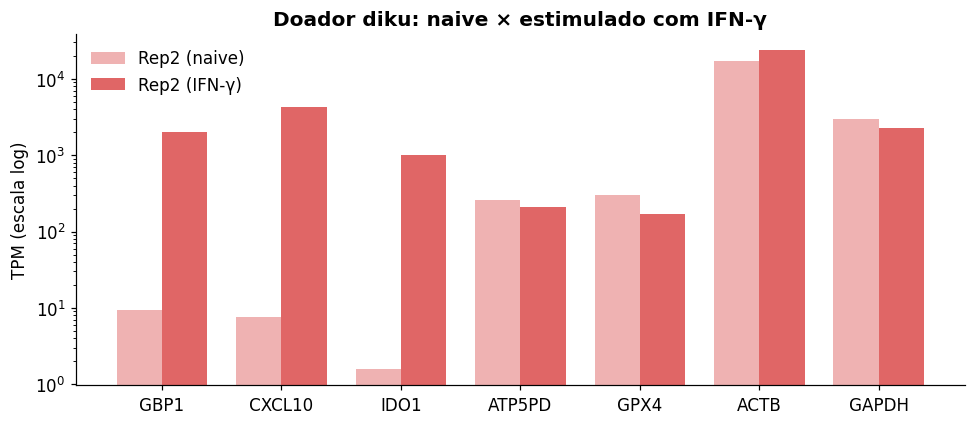

In [25]:
# Rep2 trocada pela amostra do mesmo doador (diku) estimulada com interferon-γ.
# Usamos variáveis novas (com sufixo "_ifng") para não alterar as da Parte 3.
quant_ifng = dict(quant)
quant_ifng["Rep2"] = pd.read_csv(f"{BASE}quants/SAMEA103885347/quant.sf.gz", sep="\t", index_col="Name")

# Mesmo procedimento da Parte 3: transcrito -> gene, tamanho ponderado, TPM
frag_tx_ifng = pd.DataFrame({rep: q["NumReads"] for rep, q in quant_ifng.items()})
tpm_tx_ifng  = pd.DataFrame({rep: q["TPM"]      for rep, q in quant_ifng.items()})
frag_gene_ifng = frag_tx_ifng.groupby(gene_de).sum()
pesos_ifng = tpm_tx_ifng + 1e-9
tamanho_gene_kb_ifng = (pesos_ifng.mul(tam_tx, axis=0).groupby(gene_de).sum()
                        / pesos_ifng.groupby(gene_de).sum()).mean(axis=1) / 1000
tpm_gene_ifng = tpm(frag_gene_ifng, tamanho_gene_kb_ifng, escala=1e6)

print("Fragmentos totais · Rep2 naive: "
      f"{frag_gene['Rep2'].sum() / 1e6:.1f} M  |  Rep2 IFN-γ: {frag_gene_ifng['Rep2'].sum() / 1e6:.1f} M")

# Genes de resposta ao IFN-γ e genes de controle (estáveis)
genes_ex3 = ["GBP1", "CXCL10", "IDO1", "ATP5PD", "GPX4", "ACTB", "GAPDH"]
tabela_ex3 = pd.DataFrame({
    "Rep1 (naive)": tpm_gene.loc[genes_ex3, "Rep1"],
    "Rep2 (naive)": tpm_gene.loc[genes_ex3, "Rep2"],
    "Rep2 (IFN-γ)": tpm_gene_ifng.loc[genes_ex3, "Rep2"],
    "Rep3 (naive)": tpm_gene.loc[genes_ex3, "Rep3"],
})
tabela_ex3["IFN-γ ÷ naive (Rep2)"] = tabela_ex3["Rep2 (IFN-γ)"] / tabela_ex3["Rep2 (naive)"]
mostrar(tabela_ex3, casas=1, titulo="Exercício 3 · TPM, mesmo doador antes e depois do IFN-γ")

# Gráfico em escala log: os genes de IFN-γ sobem centenas de vezes, os controles não
fig, eixo = plt.subplots(figsize=(9, 4))
x = np.arange(len(genes_ex3))
for i, (col, alpha) in enumerate([("Rep2 (naive)", 0.5), ("Rep2 (IFN-γ)", 1.0)]):
    eixo.bar(x + (i - 0.5) * 0.38, tabela_ex3[col], 0.38, color=CORES["TPM"], alpha=alpha, label=col)
eixo.set_yscale("log")
eixo.set_xticks(x, genes_ex3)
eixo.set_ylabel("TPM (escala log)")
eixo.set_title("Doador diku: naive × estimulado com IFN-γ")
eixo.legend(frameon=False)
plt.tight_layout()
plt.show()


# Exercício 4
O gene CD44 tem 39 transcritos anotados no Gencode v29, e em comparação com os analizados no exercício 3, com tamanhos que vão de 352 nt até 5.732 nt, uma diferença de mais de 16×. Eles também não são expressos da mesma forma: a isoforma mais expressa (ENST00000263398, 4.589 nt) tem TPM entre 143 e 183 nas três réplicas, enquanto várias isoformas curtas têm TPM próximo de zero. Além disso, essa proporção muda de amostra para amostra: no Rep2, por exemplo, a isoforma ENST00000525469 (705 nt) tem TPM de 24,4, e no Rep1 ela é zero.

Por isso o "tamanho do gene" depende de uma escolha. No notebook usamos a média dos tamanhos ponderada pelo TPM, que dá 2.705 nt no Rep1, 2.939 nt no Rep2 e 2.640 nt no Rep3, ou seja, um valor diferente em cada amostra (por simplicidade usamos a média, 2.761 nt). Outras escolhas seriam igualmente possíveis: o menor transcrito (352 nt), o maior (5.732 nt), a média simples (1.082 nt) ou a mediana (705 nt). Com os mesmos fragmentos do Rep1 (≈ 20.250), o TPM do CD44 fica em 423 usando o tamanho ponderado, mas vai a 204 com o maior transcrito e a 3.309 com o menor, uma variação de cerca de 16×.

Assim, quando um gene tem várias isoformas, a sua "expressão" em RPKM, FPKM ou TPM depende de como definimos o seu tamanho, e não existe um único valor correto. Por isso é mais confiável quantificar no nível de transcrito, como o Salmon faz, e só depois somar os valores por gene, ou então usar as contagens brutas com ferramentas como DESeq2 e edgeR.


In [26]:
# Transcritos do CD44: tamanho e TPM de cada um nas 3 réplicas
tx_cd44 = anotacao.index[(anotacao.gene == "CD44") & anotacao.index.isin(tam_tx.index)]
tabela_tx = pd.DataFrame({"Tamanho (nt)": tam_tx.loc[tx_cd44]}).join(tpm_tx.loc[tx_cd44])
mostrar(tabela_tx.sort_values("Tamanho (nt)"), casas=1,
        titulo=f"Exercício 4 · {len(tx_cd44)} transcritos do CD44 (TPM do Salmon)")

# Diferentes escolhas de "tamanho do gene" para o CD44
escolhas_kb = {
    "Média ponderada pelo TPM (usada no notebook)": tamanho_gene_kb["CD44"],
    "Menor transcrito":  tam_tx.loc[tx_cd44].min() / 1000,
    "Maior transcrito":  tam_tx.loc[tx_cd44].max() / 1000,
    "Média simples":     tam_tx.loc[tx_cd44].mean() / 1000,
    "Mediana":           tam_tx.loc[tx_cd44].median() / 1000,
}

# Mesmos fragmentos, só troca o tamanho do CD44 e recalcula o TPM
linhas = {}
for nome, kb in escolhas_kb.items():
    tamanhos = tamanho_gene_kb.copy()
    tamanhos["CD44"] = kb
    linhas[nome] = pd.concat([pd.Series({"Tamanho (nt)": kb * 1000}),
                              tpm(frag_gene, tamanhos, escala=1e6).loc["CD44"]])
mostrar(pd.DataFrame(linhas).T, casas=1,
        titulo="Exercício 4 · TPM do CD44 conforme a escolha do tamanho")


**Exercício 4 · 39 transcritos do CD44 (TPM do Salmon)**

,Tamanho (nt),Rep1,Rep2,Rep3
transcrito,,,,
ENST00000524922.1,352,0.0,0.0,0.0
ENST00000525241.1,440,1.5,1.4,2.1
ENST00000278386.10,484,0.0,0.5,0.0
ENST00000639002.1,528,0.0,0.0,0.0
ENST00000531141.1,537,0.0,0.1,0.0
ENST00000527889.6,548,0.0,0.0,0.0
ENST00000525688.5,560,2.6,3.3,3.4
ENST00000534082.1,564,0.2,0.0,0.3
ENST00000525348.1,568,0.0,0.0,0.1


**Exercício 4 · TPM do CD44 conforme a escolha do tamanho**

,Tamanho (nt),Rep1,Rep2,Rep3
Média ponderada pelo TPM (usada no notebook),2761.1,423.1,445.6,361.7
Menor transcrito,352.0,3308.9,3484.3,2830.6
Maior transcrito,5732.0,203.8,214.7,174.3
Média simples,1082.1,1078.8,1136.2,922.6
Mediana,705.0,1654.9,1742.7,1415.3
